In [93]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [94]:
google = yf.download("GOOGL", start="2021-01-01", end="2021-12-31", auto_adjust=False)['Adj Close']
amazon = yf.download("AMZN", start="2021-01-01", end="2021-12-31", auto_adjust=False)['Adj Close']
microsoft = yf.download("MSFT", start="2021-01-01", end="2021-12-31", auto_adjust=False)['Adj Close']
apple = yf.download("AAPL", start="2021-01-01", end="2021-12-31", auto_adjust=False)['Adj Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [95]:
prices = pd.concat([google, amazon, microsoft, apple], axis=1)
prices.columns = ["GOOGL", "AMZN", "MSFT", "AAPL"]

prices.head()

,GOOGL,AMZN,MSFT,AAPL
Date,,,,
2021-01-04,85.715317,159.331497,209.273148,126.096573
2021-01-05,86.406548,160.925507,209.475021,127.655594
2021-01-06,85.553925,156.919006,204.043503,123.358528
2021-01-07,88.109306,158.108002,209.849960,127.567932
2021-01-08,89.275757,159.134995,211.128540,128.668976


In [96]:
log_returns = np.log(prices / prices.shift(1)).dropna()
print(log_returns.head())

               GOOGL      AMZN      MSFT      AAPL
Date                                              
2021-01-05  0.008032  0.009955  0.000964  0.012288
2021-01-06 -0.009917 -0.025212 -0.026271 -0.034241
2021-01-07  0.029431  0.007549  0.028060  0.033554
2021-01-08  0.013152  0.006475  0.006074  0.008594
2021-01-11 -0.023377 -0.021754 -0.009746 -0.023523


In [97]:
# Compute log returns and build 1000 different portfolios using random weighting for these 4
# stocks).
np.random.seed(50)
n_portfolios = 1000

In [98]:
# Compute expected return, volatility and Sharpe ratio for each portfolio. Remember to annualize
# returns and volatilities!
# Mean daily returns and covariance
mean_daily_returns = log_returns.mean()
cov_matrix = log_returns.cov()

results = []

for _ in range(n_portfolios):

    weights = np.random.random(len(prices.columns))
    weights = weights / np.sum(weights)
    
    # Portfolio return
    port_return = np.dot(weights, mean_daily_returns)
    
    #Potfolio Volatility
    port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    
    # Annualize returns and vol
    ann_return = port_return * 252
    ann_vol = port_vol * np.sqrt(252)
    sharpe = ann_return / ann_vol
    
    results.append([ann_return, ann_vol, sharpe] + list(weights))

# Build dataframe
columns = ["Expected Return", "Volatility", "Sharpe"] + list(prices.columns)
portfolios = pd.DataFrame(results, columns=columns)

portfolios.head()

,Expected Return,Volatility,Sharpe,GOOGL,AMZN,MSFT,AAPL
0,0.380182,0.202257,1.879701,0.359844,0.165940,0.185868,0.288347
1,0.273026,0.202828,1.346092,0.147736,0.390204,0.159828,0.302232
2,0.393136,0.202784,1.938695,0.429961,0.175260,0.195913,0.198866
3,0.282716,0.198381,1.425114,0.056224,0.375943,0.351405,0.216428
4,0.288210,0.198380,1.452817,0.138301,0.391717,0.297503,0.172479


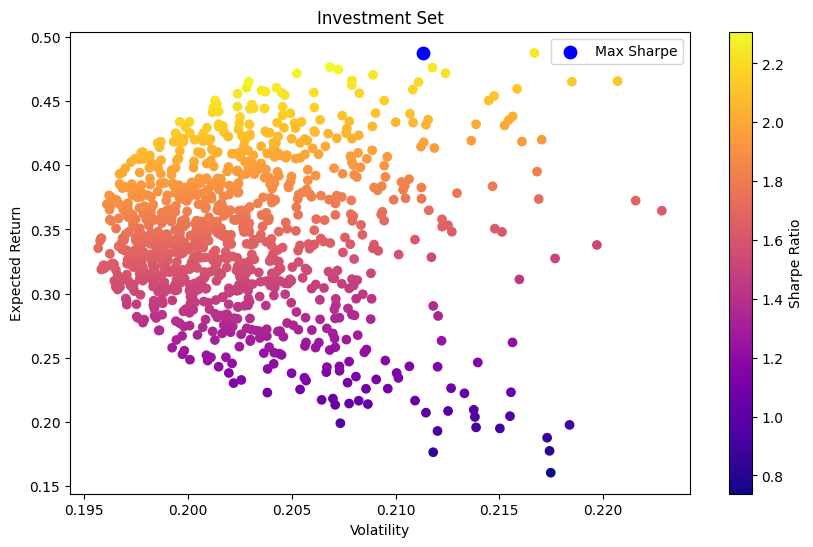

In [99]:
# Investment Set: Plot the data (scatter plot, x axis = volatilities, y axis = returns) and highlight with a
# different color the portfolio with the highest SR.

max_sharpe_port = portfolios.loc[portfolios["Sharpe"].idxmax()]

plt.figure(figsize = (10,6))

plt.scatter(portfolios["Volatility"], portfolios["Expected Return"],
            c = portfolios["Sharpe"], cmap = "plasma", alpha = 1)

plt.colorbar(label = "Sharpe Ratio")

#Max Sharpe ratio highlight
plt.scatter(max_sharpe_port["Volatility"], max_sharpe_port["Expected Return"],
            c = "blue", s = 80, label = "Max Sharpe")

plt.xlabel("Volatility")
plt.ylabel("Expected Return")
plt.title("Investment Set")
plt.legend()
plt.show()

In [100]:
# What portfolio would you chose? What considerations do you need to make in order to take this
# decision?
cov_matrix = log_returns.cov().values
inv_cov = np.linalg.inv(cov_matrix)
ones = np.ones(len(prices.columns))
w_mvp = inv_cov.dot(ones) / (ones.T.dot(inv_cov).dot(ones))

print("Porfoloio that I chose:", dict(zip(prices.columns, w_mvp)))

Porfoloio that I chose: {'GOOGL': 0.11370362030714723, 'AMZN': 0.27163795954821957, 'MSFT': 0.5144291916853403, 'AAPL': 0.10022922845929277}


In [101]:
# Find the minimum variance portfolio
min_vol_idx = portfolios["Volatility"].idxmin()
min_vol_port = portfolios.loc[min_vol_idx]
print(min_vol_port)

Expected Return    0.335405
Volatility         0.195667
Sharpe             1.714161
GOOGL              0.054844
AMZN               0.289894
MSFT               0.584290
AAPL               0.070972
Name: 733, dtype: float64
